<h1 style="font-family: 'Times New Roman'; text-align: center;"><b>Machine Learning</b></h1>

<h2 style="font-family: 'Times New Roman'; text-align: center;"><b>URL Phishing Detection Project</b></h2>

<h3 style="font-family: 'Times New Roman'; text-align: right;"><b>- Pallav Biyala (24110234)</b></h3>

<hr>

<h2 style="font-family: 'Times New Roman'; text-align: center;"><b> Decision Trees, Bagging & Boosting </b></h2>

### Importing Libraries

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    confusion_matrix,
    balanced_accuracy_score
)
import time

In [24]:
df = pd.read_csv("../data/PhiUSIIL_Phishing_URL_Dataset.csv")

<hr>

<h3 style="font-family: 'Times New Roman';"><b> Pre-Processing of the Data</b></h3>

In [25]:
# Remove repeated URLs before splitting.
df = df.drop_duplicates(subset=["URL"], keep="first").copy()

# All 50 numeric input features, excluding the target.
all_numeric_features = [
    c for c in df.select_dtypes(include=np.number).columns
    if c != "label"
]

print("Total numeric features:", len(all_numeric_features))

# M1: Strict lexical URL features.
lexical_features = [
    "URLLength", "DomainLength", "TLDLength", "NoOfSubDomain",
    "NoOfLettersInURL", "LetterRatioInURL",
    "NoOfDegitsInURL", "DegitRatioInURL",
    "NoOfEqualsInURL", "NoOfQMarkInURL",
    "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL", "IsDomainIP",
    "HasObfuscation", "NoOfObfuscatedChar", "ObfuscationRatio"
]

# M2: Add the three derived statistical features.
derived_features = [
    "TLDLegitimateProb",
    "URLCharProb",
    "CharContinuationRate"
]
# M3 adds HTTPS along with lexial and derived features --> represents what we can have if we are just given URL
# M4: Add HTTPS and the page-dependent features.
# URLSimilarityIndex is deliberately reserved for M5.
page_features = [
    c for c in all_numeric_features
    if c not in lexical_features
    and c not in derived_features
    and c not in ["IsHTTPS", "URLSimilarityIndex"]
]

feature_sets = {
    "M1 - Lexical": lexical_features,

    "M2 - Derived": (
        lexical_features + derived_features
    ),

    "M3 - URL Features": (
        lexical_features + derived_features + ["IsHTTPS"]
    ),

    "M4 - Page-aware": (
        lexical_features
        + derived_features
        + ["IsHTTPS"]
        + page_features
    ),

    "M5 - All numeric": all_numeric_features
}

for name, features in feature_sets.items():
    missing = set(features) - set(df.columns)
    assert not missing, f"{name}: missing columns {missing}"
    assert len(features) == len(set(features)), (
        f"{name}: duplicate feature names"
    )
    print(f"{name}: {len(features)} features")

assert "URLSimilarityIndex" not in feature_sets["M4 - Page-aware"]
assert "URLSimilarityIndex" in feature_sets["M5 - All numeric"]

Total numeric features: 50
M1 - Lexical: 17 features
M2 - Derived: 20 features
M3 - URL Features: 21 features
M4 - Page-aware: 49 features
M5 - All numeric: 50 features


In [26]:
X = df[all_numeric_features]
y = df["label"]

# 80% train+validation, 10% test.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

# Split the remaining 90% into 80% train and 10% validation
# of the original dataset.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=1/9,
    random_state=42,
    stratify=y_train_val
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 188296
Validation: 23537
Test: 23537


<hr>

<h2 style="font-family: 'Times New Roman'; text-align: center;"><b> Decision Trees</b></h2>

In [27]:
dt_results = []

for name, feature in feature_sets.items():
    # Growing trees
    dt = DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    )

    start = time.time()

    dt.fit(X_train[feature], y_train)
    y_train_pred = dt.predict(X_train[feature])
    train_accuracy = accuracy_score(y_train, y_train_pred)

    training_time = time.time() - start

    # Finding the metrics
    y_val_pred = dt.predict(X_val[feature])

    cm = confusion_matrix(
        y_val, y_val_pred, labels=[0, 1]
    )

    result = {
        "Model": name,
        "Features": len(feature),
        "Training Time (s)": round(training_time, 2),
        "Train Accuracy": round(train_accuracy, 4),
        "Validation Accuracy": round(
            accuracy_score(y_val, y_val_pred), 4
        ),
        "Generalization Gap": round(
            train_accuracy - accuracy_score(y_val, y_val_pred), 4
        ),
        "Balanced Accuracy": round(balanced_accuracy_score(
            y_val, y_val_pred
        ),4),
        "Phishing Recall": round(recall_score(
            y_val, y_val_pred, pos_label=0
        ),4),
        "Missed Phishing": cm[0, 1],
        "False Alarms": cm[1, 0],
        "Depth": dt.get_depth(),
        "Leaves": dt.get_n_leaves()
    }

    dt_results.append(result)

    print(f"\n{name}")
    for key, value in result.items():
        if key != "Model":
            print(f"{key}: {value}")

    print("Confusion matrix:\n", cm)


M1 - Lexical
Features: 17
Training Time (s): 1.66
Train Accuracy: 0.9984
Validation Accuracy: 0.9962
Generalization Gap: 0.0021
Balanced Accuracy: 0.996
Phishing Recall: 0.9943
Missed Phishing: 57
False Alarms: 32
Depth: 26
Leaves: 885
Confusion matrix:
 [[ 9995    57]
 [   32 13453]]

M2 - Derived
Features: 20
Training Time (s): 2.0
Train Accuracy: 1.0
Validation Accuracy: 0.992
Generalization Gap: 0.008
Balanced Accuracy: 0.9919
Phishing Recall: 0.9908
Missed Phishing: 92
False Alarms: 96
Depth: 34
Leaves: 1808
Confusion matrix:
 [[ 9960    92]
 [   96 13389]]

M3 - URL Features
Features: 21
Training Time (s): 1.79
Train Accuracy: 1.0
Validation Accuracy: 0.9945
Generalization Gap: 0.0055
Balanced Accuracy: 0.9945
Phishing Recall: 0.994
Missed Phishing: 60
False Alarms: 69
Depth: 48
Leaves: 1105
Confusion matrix:
 [[ 9992    60]
 [   69 13416]]

M4 - Page-aware
Features: 49
Training Time (s): 6.28
Train Accuracy: 1.0
Validation Accuracy: 0.9991
Generalization Gap: 0.0009
Balanced Ac

### Depth test

In [28]:
def train_with_limited_height(
    name,
    feature,
    max_depths=[3, 5, 10, 15, 20, None]
):
    results = []

    for depth in max_depths:
        # Train the tree
        dt = DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            random_state=42
        )

        start = time.time()
        dt.fit(X_train[feature], y_train)
        y_train_pred = dt.predict(X_train[feature])
        train_accuracy = accuracy_score(y_train, y_train_pred)
        
        training_time = time.time() - start

        # Predict on validation data
        y_val_pred = dt.predict(X_val[feature])

        cm = confusion_matrix(
            y_val, y_val_pred, labels=[0, 1]
        )

        result = {
            "Model": name,
            "Features": len(feature),
            "Max Depth Setting": depth,
            "Training Time (s)": round(training_time, 2),
            "Train Accuracy": round(train_accuracy, 4),
            "Validation Accuracy": round(
                accuracy_score(y_val, y_val_pred), 4
            ),
            "Generalization Gap": round(
                train_accuracy - accuracy_score(y_val, y_val_pred), 4
            ),
            "Balanced Accuracy": round(
                balanced_accuracy_score(y_val, y_val_pred), 4
            ),
            "Phishing Recall": round(
                recall_score(y_val, y_val_pred, pos_label=0), 4
            ),
            "Missed Phishing": cm[0, 1],
            "False Alarms": cm[1, 0],
            "Actual Depth": dt.get_depth(),
            "Leaves": dt.get_n_leaves()
        }

        results.append(result)

        print(f"\n{name} | max_depth={depth}")
        for key, value in result.items():
            if key != "Model":
                print(f"{key}: {value}")

        print("Confusion matrix:\n", cm)

    return results

In [29]:
m1_depth_results = train_with_limited_height(
    "M1 - Lexical",
    lexical_features
)


M1 - Lexical | max_depth=3
Features: 17
Max Depth Setting: 3
Training Time (s): 0.49
Train Accuracy: 0.8414
Validation Accuracy: 0.8422
Generalization Gap: -0.0008
Balanced Accuracy: 0.8213
Phishing Recall: 0.678
Missed Phishing: 3237
False Alarms: 477
Actual Depth: 3
Leaves: 8
Confusion matrix:
 [[ 6815  3237]
 [  477 13008]]

M1 - Lexical | max_depth=5
Features: 17
Max Depth Setting: 5
Training Time (s): 0.72
Train Accuracy: 0.8605
Validation Accuracy: 0.861
Generalization Gap: -0.0006
Balanced Accuracy: 0.8415
Phishing Recall: 0.7073
Missed Phishing: 2942
False Alarms: 329
Actual Depth: 5
Leaves: 27
Confusion matrix:
 [[ 7110  2942]
 [  329 13156]]

M1 - Lexical | max_depth=10
Features: 17
Max Depth Setting: 10
Training Time (s): 0.92
Train Accuracy: 0.9536
Validation Accuracy: 0.9507
Generalization Gap: 0.0029
Balanced Accuracy: 0.9463
Phishing Recall: 0.9165
Missed Phishing: 839
False Alarms: 322
Actual Depth: 10
Leaves: 325
Confusion matrix:
 [[ 9213   839]
 [  322 13163]]

M1 -

### Leaf Test:

In [30]:
def train_with_limited_leaf_size(
    name,
    feature,
    leaf_sizes=[1, 2, 5, 10, 20, 50, 100]
):
    results = []

    for leaf_size in leaf_sizes:
        dt = DecisionTreeClassifier(
            criterion="gini",
            min_samples_leaf=leaf_size,
            random_state=42
        )

        start = time.time()
        dt.fit(X_train[feature], y_train)
        training_time = time.time() - start

        y_train_pred = dt.predict(X_train[feature])
        y_val_pred = dt.predict(X_val[feature])

        cm = confusion_matrix(
            y_val, y_val_pred, labels=[0, 1]
        )

        result = {
            "Model": name,
            "Features": len(feature),
            "Min Samples Leaf": leaf_size,
            "Training Time (s)": round(training_time, 2),
            "Train Accuracy": round(
                accuracy_score(y_train, y_train_pred), 4
            ),
            "Validation Accuracy": round(
                accuracy_score(y_val, y_val_pred), 4
            ),
            "Generalization Gap": round(
                accuracy_score(y_train, y_train_pred) - accuracy_score(y_val, y_val_pred), 4
            ),
            "Balanced Accuracy": round(
                balanced_accuracy_score(y_val, y_val_pred), 4
            ),
            "Phishing Recall": round(
                recall_score(y_val, y_val_pred, pos_label=0), 4
            ),
            "Missed Phishing": cm[0, 1],
            "False Alarms": cm[1, 0],
            "Depth": dt.get_depth(),
            "Leaves": dt.get_n_leaves()
        }

        results.append(result)

        print(f"\n{name} | min_samples_leaf={leaf_size}")
        for key, value in result.items():
            if key != "Model":
                print(f"{key}: {value}")

        print("Confusion matrix:\n", cm)

    return results

In [31]:
m1_leaf_results = train_with_limited_leaf_size(
    "M1 - Lexical",
    lexical_features
)


M1 - Lexical | min_samples_leaf=1
Features: 17
Min Samples Leaf: 1
Training Time (s): 1.54
Train Accuracy: 0.9984
Validation Accuracy: 0.9962
Generalization Gap: 0.0021
Balanced Accuracy: 0.996
Phishing Recall: 0.9943
Missed Phishing: 57
False Alarms: 32
Depth: 26
Leaves: 885
Confusion matrix:
 [[ 9995    57]
 [   32 13453]]

M1 - Lexical | min_samples_leaf=2
Features: 17
Min Samples Leaf: 2
Training Time (s): 1.56
Train Accuracy: 0.9978
Validation Accuracy: 0.9956
Generalization Gap: 0.0021
Balanced Accuracy: 0.9954
Phishing Recall: 0.994
Missed Phishing: 60
False Alarms: 43
Depth: 25
Leaves: 815
Confusion matrix:
 [[ 9992    60]
 [   43 13442]]

M1 - Lexical | min_samples_leaf=5
Features: 17
Min Samples Leaf: 5
Training Time (s): 1.09
Train Accuracy: 0.9965
Validation Accuracy: 0.9951
Generalization Gap: 0.0014
Balanced Accuracy: 0.9947
Phishing Recall: 0.9925
Missed Phishing: 75
False Alarms: 41
Depth: 23
Leaves: 662
Confusion matrix:
 [[ 9977    75]
 [   41 13444]]

M1 - Lexical |

### Splitting Criteria

In [32]:
criteria = ["gini", "entropy", "log_loss"]

criterion_results = []

for name, feature in feature_sets.items():
    for criterion in criteria:

        dt = DecisionTreeClassifier(
            criterion=criterion,
            random_state=42
        )

        start = time.time()

        dt.fit(X_train[feature], y_train)

        training_time = time.time() - start

        y_train_pred = dt.predict(X_train[feature])
        y_val_pred = dt.predict(X_val[feature])

        cm = confusion_matrix(
            y_val, y_val_pred, labels=[0, 1]
        )

        result = {
            "Model": name,
            "Criterion": criterion,
            "Features": len(feature),
            "Training Time (s)": round(training_time, 2),
            "Train Accuracy": round(
                accuracy_score(y_train, y_train_pred), 4
            ),
            "Validation Accuracy": round(
                accuracy_score(y_val, y_val_pred), 4
            ),
            "Generalization Gap": round(
                accuracy_score(y_train, y_train_pred) - accuracy_score(y_val, y_val_pred), 4
            ),
            "Balanced Accuracy": round(
                balanced_accuracy_score(y_val, y_val_pred), 4
            ),
            "Phishing Recall": round(
                recall_score(y_val, y_val_pred, pos_label=0), 4
            ),
            "Missed Phishing": cm[0, 1],
            "False Alarms": cm[1, 0],
            "Depth": dt.get_depth(),
            "Leaves": dt.get_n_leaves()
        }

        criterion_results.append(result)

        print(f"\n{name} | criterion={criterion}")

        for key, value in result.items():
            if key != "Model":
                print(f"{key}: {value}")

        print("Confusion matrix:\n", cm)


M1 - Lexical | criterion=gini
Criterion: gini
Features: 17
Training Time (s): 0.95
Train Accuracy: 0.9984
Validation Accuracy: 0.9962
Generalization Gap: 0.0021
Balanced Accuracy: 0.996
Phishing Recall: 0.9943
Missed Phishing: 57
False Alarms: 32
Depth: 26
Leaves: 885
Confusion matrix:
 [[ 9995    57]
 [   32 13453]]

M1 - Lexical | criterion=entropy
Criterion: entropy
Features: 17
Training Time (s): 0.93
Train Accuracy: 0.9984
Validation Accuracy: 0.9962
Generalization Gap: 0.0022
Balanced Accuracy: 0.9959
Phishing Recall: 0.994
Missed Phishing: 60
False Alarms: 30
Depth: 26
Leaves: 882
Confusion matrix:
 [[ 9992    60]
 [   30 13455]]

M1 - Lexical | criterion=log_loss
Criterion: log_loss
Features: 17
Training Time (s): 0.82
Train Accuracy: 0.9984
Validation Accuracy: 0.9962
Generalization Gap: 0.0022
Balanced Accuracy: 0.9959
Phishing Recall: 0.994
Missed Phishing: 60
False Alarms: 30
Depth: 26
Leaves: 882
Confusion matrix:
 [[ 9992    60]
 [   30 13455]]

M2 - Derived | criterion=

<hr>

<h2 style="font-family: 'Times New Roman'; text-align: center;"><b> Bagging: Random Forests </b></h2>

In [33]:
## Model --> Random Forest
rf_results = []
for name, feature in feature_sets.items():
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    start = time.time()

    rf.fit(X_train[feature], y_train)

    training_time = time.time() - start

    y_train_pred = rf.predict(X_train[feature])
    y_val_pred = rf.predict(X_val[feature])

    cm = confusion_matrix(
        y_val,
        y_val_pred,
        labels=[0, 1]
    )

    result = {
        "Model": name,
        "Features": len(feature),
        "Training Time (s)": round(training_time, 2),
        "Train Accuracy": round(
            accuracy_score(y_train, y_train_pred), 4
        ),
        "Validation Accuracy": round(
            accuracy_score(y_val, y_val_pred), 4
        ),
        "Generalization Gap": round(
                accuracy_score(y_train, y_train_pred) - accuracy_score(y_val, y_val_pred), 4
        ),
        "Balanced Accuracy": round(
            balanced_accuracy_score(y_val, y_val_pred), 4
        ),
        "Phishing Recall": round(
            recall_score(y_val, y_val_pred, pos_label=0), 4
        ),
        "Missed Phishing": int(cm[0, 1]),
        "False Alarms": int(cm[1, 0])
    }

    rf_results.append(result)

    print(f"\n{name}")
    for key, value in result.items():
        print(f"{key}: {value}")

    print("Confusion matrix:\n", cm)

rf_results_df = pd.DataFrame(rf_results)

print("\n===== RANDOM FOREST BASELINE SUMMARY =====")
rf_results_df


M1 - Lexical
Model: M1 - Lexical
Features: 17
Training Time (s): 8.8
Train Accuracy: 0.9984
Validation Accuracy: 0.9966
Generalization Gap: 0.0018
Balanced Accuracy: 0.9963
Phishing Recall: 0.9945
Missed Phishing: 55
False Alarms: 26
Confusion matrix:
 [[ 9997    55]
 [   26 13459]]

M2 - Derived
Model: M2 - Derived
Features: 20
Training Time (s): 13.5
Train Accuracy: 1.0
Validation Accuracy: 0.9951
Generalization Gap: 0.0049
Balanced Accuracy: 0.995
Phishing Recall: 0.9942
Missed Phishing: 58
False Alarms: 58
Confusion matrix:
 [[ 9994    58]
 [   58 13427]]

M3 - URL Features
Model: M3 - URL Features
Features: 21
Training Time (s): 16.11
Train Accuracy: 1.0
Validation Accuracy: 0.9965
Generalization Gap: 0.0035
Balanced Accuracy: 0.9962
Phishing Recall: 0.9945
Missed Phishing: 55
False Alarms: 28
Confusion matrix:
 [[ 9997    55]
 [   28 13457]]

M4 - Page-aware
Model: M4 - Page-aware
Features: 49
Training Time (s): 20.96
Train Accuracy: 1.0
Validation Accuracy: 0.9999
Generalizatio

,Model,Features,Training Time (s),Train Accuracy,Validation Accuracy,Generalization Gap,Balanced Accuracy,Phishing Recall,Missed Phishing,False Alarms
0,M1 - Lexical,17,8.80,0.9984,0.9966,0.0018,0.9963,0.9945,55,26
1,M2 - Derived,20,13.50,1.0000,0.9951,0.0049,0.9950,0.9942,58,58
2,M3 - URL Features,21,16.11,1.0000,0.9965,0.0035,0.9962,0.9945,55,28
3,M4 - Page-aware,49,20.96,1.0000,0.9999,0.0001,0.9999,0.9998,2,0
4,M5 - All numeric,50,13.45,1.0000,1.0000,0.0000,1.0000,1.0000,0,0


### No. of trees max possible in forest:

In [34]:
## Model --> Random Forest
rf_results = []
max_trees = [10, 25, 50, 100, 200]

for name, feature in feature_sets.items():
    for n in max_trees:     
        rf = RandomForestClassifier(
            n_estimators=n,
            random_state=42,
            n_jobs=-1
        )
    
        start = time.time()
    
        rf.fit(X_train[feature], y_train)
    
        training_time = time.time() - start
    
        y_train_pred = rf.predict(X_train[feature])
        y_val_pred = rf.predict(X_val[feature])
    
        cm = confusion_matrix(
            y_val,
            y_val_pred,
            labels=[0, 1]
        )
    
        result = {
            "Model": name,
            "Max Trees Allowed" : n,
            "Features": len(feature),
            "Training Time (s)": round(training_time, 2),
            "Train Accuracy": round(
                accuracy_score(y_train, y_train_pred), 4
            ),
            "Validation Accuracy": round(
                accuracy_score(y_val, y_val_pred), 4
            ),
            "Generalization Gap": round(
                    accuracy_score(y_train, y_train_pred) - accuracy_score(y_val, y_val_pred), 4
            ),
            "Balanced Accuracy": round(
                balanced_accuracy_score(y_val, y_val_pred), 4
            ),
            "Phishing Recall": round(
                recall_score(y_val, y_val_pred, pos_label=0), 4
            ),
            "Missed Phishing": int(cm[0, 1]),
            "False Alarms": int(cm[1, 0])
        }
    
        rf_results.append(result)
    
        print(f"\n{name}")
        for key, value in result.items():
            print(f"{key}: {value}")
    
        print("Confusion matrix:\n", cm)

rf_results_df = pd.DataFrame(rf_results)

print("\n===== RANDOM FOREST BASELINE SUMMARY =====")
rf_results_df


M1 - Lexical
Model: M1 - Lexical
Max Trees Allowed: 10
Features: 17
Training Time (s): 1.65
Train Accuracy: 0.9982
Validation Accuracy: 0.9964
Generalization Gap: 0.0018
Balanced Accuracy: 0.9962
Phishing Recall: 0.9945
Missed Phishing: 55
False Alarms: 30
Confusion matrix:
 [[ 9997    55]
 [   30 13455]]

M1 - Lexical
Model: M1 - Lexical
Max Trees Allowed: 25
Features: 17
Training Time (s): 3.64
Train Accuracy: 0.9984
Validation Accuracy: 0.9965
Generalization Gap: 0.0018
Balanced Accuracy: 0.9963
Phishing Recall: 0.9944
Missed Phishing: 56
False Alarms: 26
Confusion matrix:
 [[ 9996    56]
 [   26 13459]]

M1 - Lexical
Model: M1 - Lexical
Max Trees Allowed: 50
Features: 17
Training Time (s): 4.21
Train Accuracy: 0.9984
Validation Accuracy: 0.9968
Generalization Gap: 0.0016
Balanced Accuracy: 0.9965
Phishing Recall: 0.9949
Missed Phishing: 51
False Alarms: 25
Confusion matrix:
 [[10001    51]
 [   25 13460]]

M1 - Lexical
Model: M1 - Lexical
Max Trees Allowed: 100
Features: 17
Traini

,Model,Max Trees Allowed,Features,Training Time (s),Train Accuracy,Validation Accuracy,Generalization Gap,Balanced Accuracy,Phishing Recall,Missed Phishing,False Alarms
0,M1 - Lexical,10,17,1.65,0.9982,0.9964,0.0018,0.9962,0.9945,55,30
1,M1 - Lexical,25,17,3.64,0.9984,0.9965,0.0018,0.9963,0.9944,56,26
2,M1 - Lexical,50,17,4.21,0.9984,0.9968,0.0016,0.9965,0.9949,51,25
3,M1 - Lexical,100,17,11.15,0.9984,0.9966,0.0018,0.9963,0.9945,55,26
4,M1 - Lexical,200,17,18.25,0.9984,0.9964,0.0019,0.9962,0.9944,56,28
5,M2 - Derived,10,20,1.35,0.9997,0.9947,0.0049,0.9947,0.9948,52,72
6,M2 - Derived,25,20,3.34,0.9999,0.9952,0.0046,0.9951,0.9942,58,54
7,M2 - Derived,50,20,6.64,1.0000,0.9950,0.0050,0.9949,0.9940,60,58
8,M2 - Derived,100,20,13.38,1.0000,0.9951,0.0049,0.9950,0.9942,58,58
9,M2 - Derived,200,20,26.42,1.0000,0.9950,0.0049,0.9949,0.9940,60,57


### So clearly, the best n we found is:
#### M1 -->50
#### M2 -->25
#### M3 -->25
#### M4 -->50 or 100 or 200
#### M5 --> Dont care

### Feature Importance:


M1 - Lexical — Top 15 Features:
                   Feature   Importance
          LetterRatioInURL 2.387746e-01
     SpacialCharRatioInURL 1.380157e-01
NoOfOtherSpecialCharsInURL 1.307471e-01
          NoOfLettersInURL 1.032814e-01
                 URLLength 9.639337e-02
           NoOfDegitsInURL 8.748567e-02
           DegitRatioInURL 7.262486e-02
              DomainLength 6.428121e-02
             NoOfSubDomain 4.256541e-02
                 TLDLength 2.490942e-02
            NoOfQMarkInURL 7.552616e-04
        NoOfAmpersandInURL 1.087332e-04
           NoOfEqualsInURL 5.189489e-05
                IsDomainIP 5.424639e-06
        NoOfObfuscatedChar 9.586927e-09


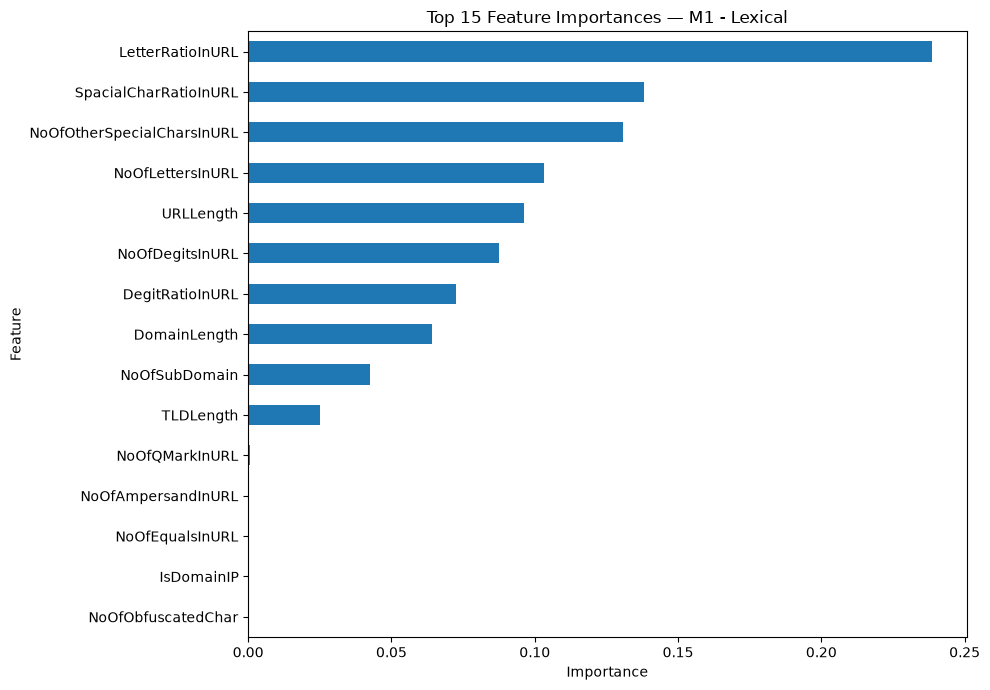


M2 - Derived — Top 15 Features:
                   Feature  Importance
          LetterRatioInURL    0.195605
           NoOfDegitsInURL    0.118730
NoOfOtherSpecialCharsInURL    0.108014
     SpacialCharRatioInURL    0.105542
                 URLLength    0.083032
          NoOfLettersInURL    0.082022
           DegitRatioInURL    0.081289
         TLDLegitimateProb    0.055016
              DomainLength    0.048413
             NoOfSubDomain    0.042535
      CharContinuationRate    0.036423
               URLCharProb    0.024155
                 TLDLength    0.019116
           NoOfEqualsInURL    0.000050
            NoOfQMarkInURL    0.000049


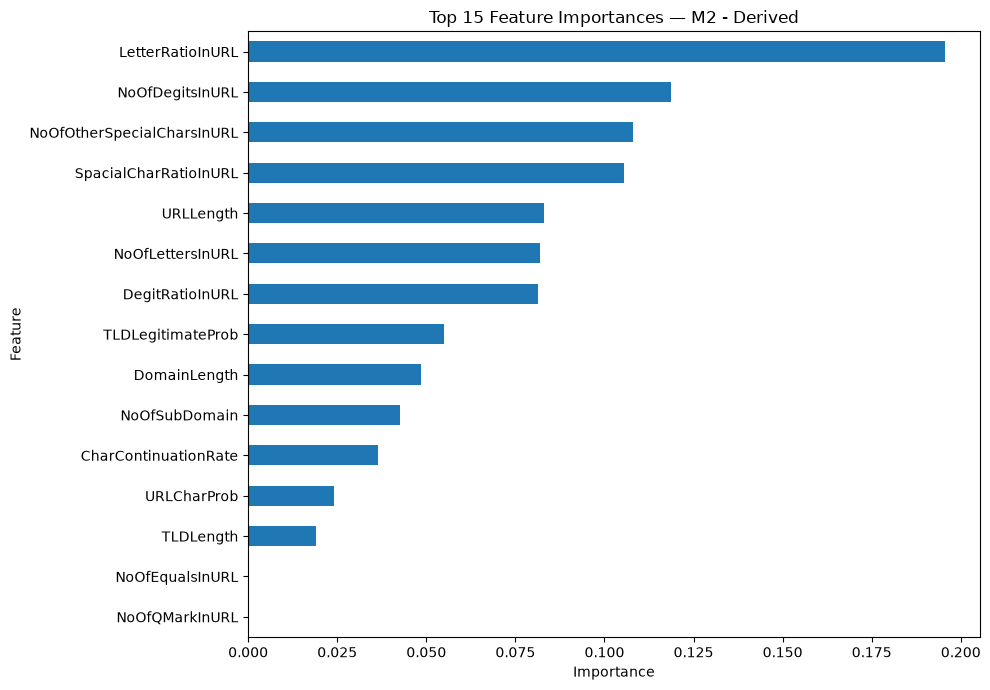


M3 - URL Features — Top 15 Features:
                   Feature  Importance
                   IsHTTPS    0.365587
NoOfOtherSpecialCharsInURL    0.118858
          LetterRatioInURL    0.085155
                 URLLength    0.073898
           NoOfDegitsInURL    0.063239
           DegitRatioInURL    0.056896
     SpacialCharRatioInURL    0.053536
          NoOfLettersInURL    0.049310
               URLCharProb    0.037489
             NoOfSubDomain    0.030326
         TLDLegitimateProb    0.028150
              DomainLength    0.016230
      CharContinuationRate    0.011585
                 TLDLength    0.007921
            NoOfQMarkInURL    0.001786


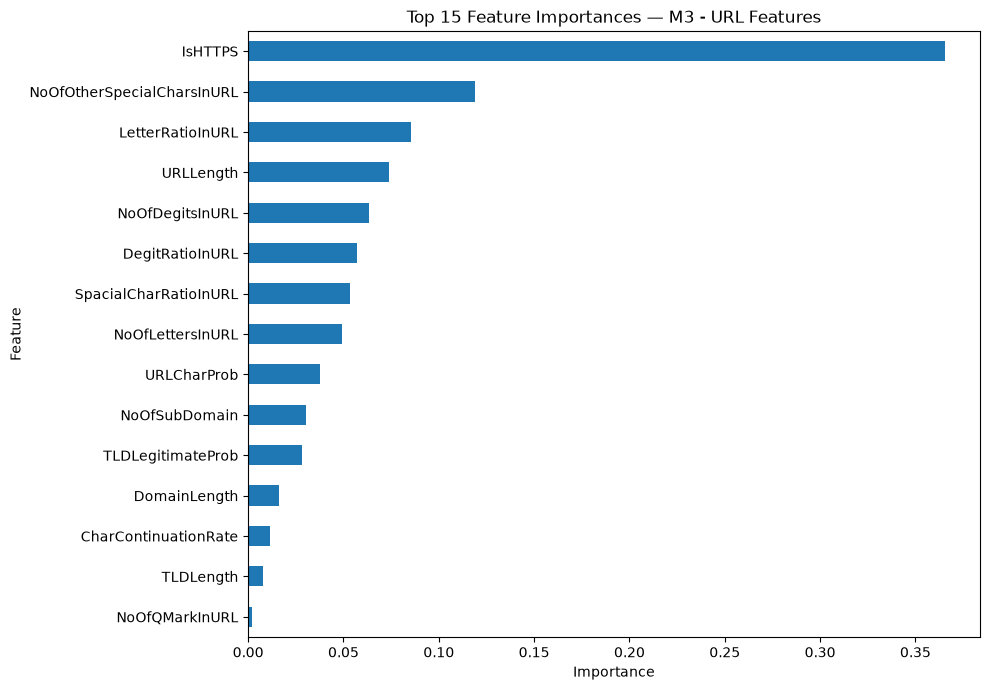


M4 - Page-aware — Top 15 Features:
                   Feature  Importance
                LineOfCode    0.146338
           NoOfExternalRef    0.139000
               NoOfSelfRef    0.126135
                 NoOfImage    0.111963
                    NoOfJS    0.076331
              HasSocialNet    0.054454
NoOfOtherSpecialCharsInURL    0.053723
                   NoOfCSS    0.049012
          HasCopyrightInfo    0.046353
         LargestLineLength    0.044489
            HasDescription    0.042527
                   IsHTTPS    0.025814
                 URLLength    0.014219
     DomainTitleMatchScore    0.009741
              IsResponsive    0.007627


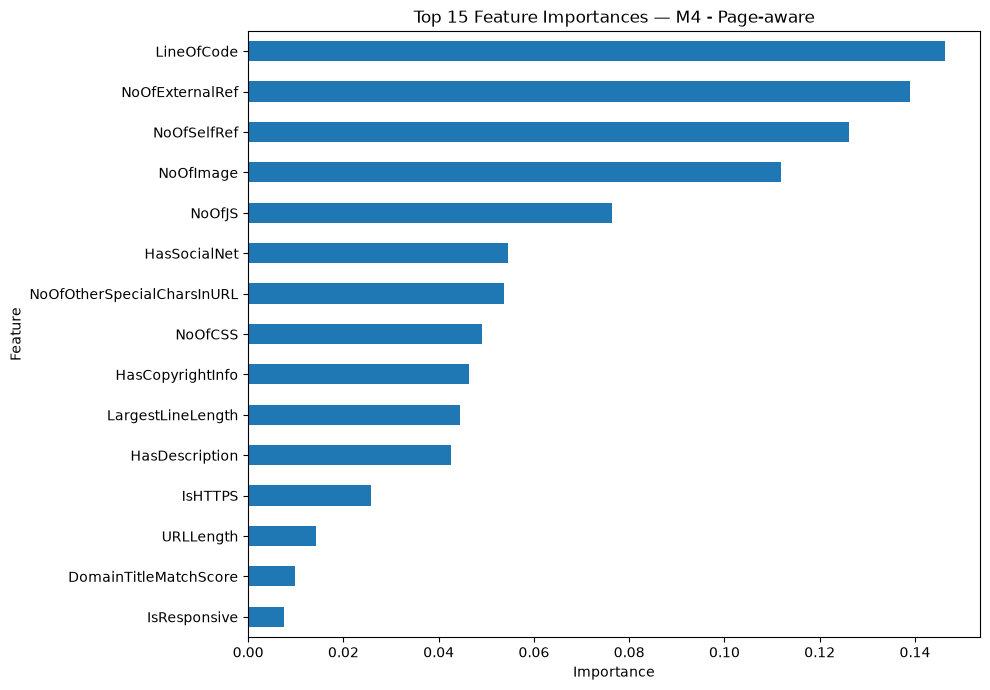


M5 - All numeric — Top 15 Features:
           Feature  Importance
URLSimilarityIndex    0.235499
       NoOfSelfRef    0.127616
        LineOfCode    0.118997
            NoOfJS    0.104906
         NoOfImage    0.104268
   NoOfExternalRef    0.085673
    HasDescription    0.041874
      HasSocialNet    0.030779
           NoOfCSS    0.026877
 LargestLineLength    0.018255
           IsHTTPS    0.018243
         URLLength    0.013275
URLTitleMatchScore    0.013145
      IsResponsive    0.011996
      NoOfEmptyRef    0.007918


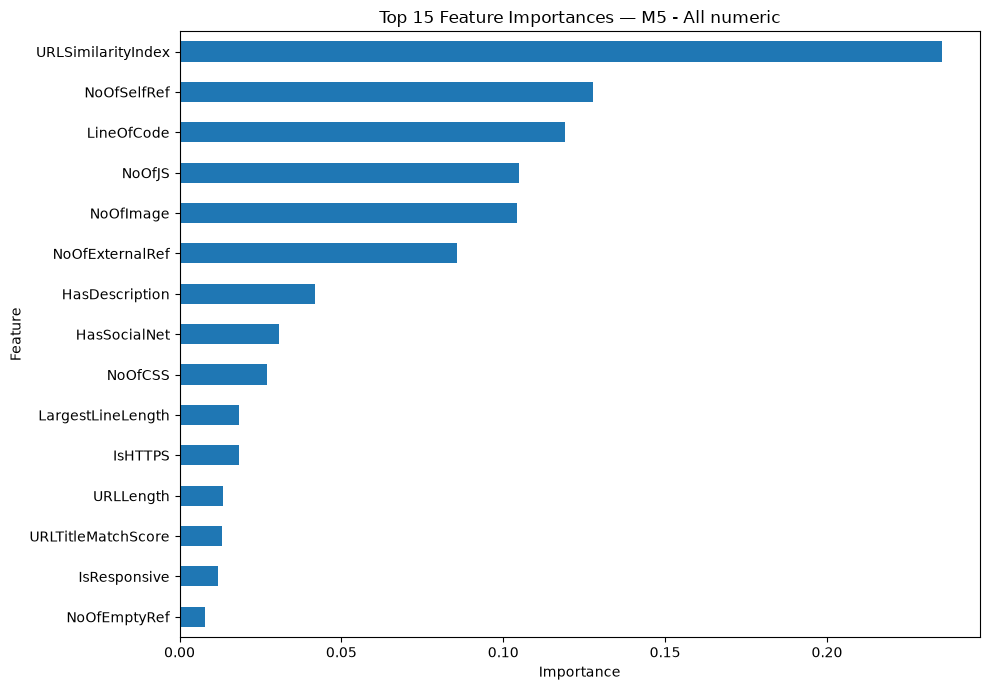

In [35]:
best_n = [50, 25, 25, 50, 25]

for i, (name, feature) in enumerate(feature_sets.items()):
    rf = RandomForestClassifier(
        n_estimators=best_n[i],
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train[feature], y_train)

    importance_df = pd.DataFrame({
        "Feature": feature,
        "Importance": rf.feature_importances_
    }).sort_values(
        by="Importance",
        ascending=False
    )

    print(f"\n{name} — Top 15 Features:")
    print(importance_df.head(15).to_string(index=False))

    importance_df.head(15).sort_values(
        "Importance"
    ).plot(
        x="Feature",
        y="Importance",
        kind="barh",
        legend=False,
        figsize=(10, 7)
    )

    plt.title(f"Top 15 Feature Importances — {name}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


<hr>

<h2 style="font-family: 'Times New Roman'; text-align: center;"><b> Boosting </b></h2>

### Gradient Boosting

In [36]:
gb_results = []

for name, feature in feature_sets.items():
    gb = GradientBoostingClassifier(
        random_state=42
    )

    start = time.time()

    gb.fit(X_train[feature], y_train)

    train_time = time.time() - start

    train_pred = gb.predict(X_train[feature])
    val_pred = gb.predict(X_val[feature])

    cm = confusion_matrix(y_val, val_pred, labels=[0, 1])

    gb_results.append({
        "Model": name,
        "Features": len(feature),
        "Training Time (s)": round(train_time, 2),
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, val_pred),
        "Phishing Recall": recall_score(
            y_val, val_pred, pos_label=0
        ),
        "Missed Phishing": cm[0, 1],
        "False Alarms": cm[1, 0],
        "Generalization Gap": (
            accuracy_score(y_train, train_pred)
            - accuracy_score(y_val, val_pred)
        )
    })

    print(f"\n{name}")
    print("Confusion Matrix:")
    print(cm)

gb_results_df = pd.DataFrame(gb_results)

print("\n=== Gradient Boosting Baseline Results ===")

gb_results_df


M1 - Lexical
Confusion Matrix:
[[ 9422   630]
 [  227 13258]]

M2 - Derived
Confusion Matrix:
[[ 9471   581]
 [  213 13272]]

M3 - URL Features
Confusion Matrix:
[[ 9969    83]
 [   29 13456]]

M4 - Page-aware
Confusion Matrix:
[[10048     4]
 [    2 13483]]

M5 - All numeric
Confusion Matrix:
[[10052     0]
 [    0 13485]]

=== Gradient Boosting Baseline Results ===


,Model,Features,Training Time (s),Train Accuracy,Validation Accuracy,Balanced Accuracy,Phishing Recall,Missed Phishing,False Alarms,Generalization Gap
0,M1 - Lexical,17,46.52,0.962522,0.963589,0.960246,0.937326,630,227,-0.001067
1,M2 - Derived,20,52.69,0.964699,0.966266,0.963203,0.942201,581,213,-0.001567
2,M3 - URL Features,21,55.95,0.995640,0.995242,0.994796,0.991743,83,29,0.000398
3,M4 - Page-aware,49,114.66,0.999899,0.999745,0.999727,0.999602,4,2,0.000154
4,M5 - All numeric,50,96.07,1.000000,1.000000,1.000000,1.000000,0,0,0.000000


#### Hyperparameter Tuning

#### No. of trees:

In [ ]:
n_estimators_values = [50, 100, 150, 200]

gb_tuning_results = []

for name, features in feature_sets.items():
    for n in n_estimators_values:
        gb = GradientBoostingClassifier(
            n_estimators=n,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        )

        start = time.time()
        gb.fit(X_train[features], y_train)
        train_time = time.time() - start

        train_pred = gb.predict(X_train[features])
        val_pred = gb.predict(X_val[features])

        cm = confusion_matrix(y_val, val_pred, labels=[0, 1])

        gb_tuning_results.append({
            "Model": name,
            "n_estimators": n,
            "Training Time (s)": round(train_time, 2),
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "Validation Accuracy": accuracy_score(y_val, val_pred),
            "Phishing Recall": recall_score(
                y_val, val_pred, pos_label=0
            ),
            "Missed Phishing": cm[0, 1],
            "False Alarms": cm[1, 0]
        })

gb_tuning_df = pd.DataFrame(gb_tuning_results)
print(gb_tuning_df.to_string(index=False))

#### Learning Rate

In [ ]:
learning_rates = [0.03, 0.1, 0.3]
gb_lr_results = []

for name, features in feature_sets.items():
    for lr in learning_rates:

        gb = GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=lr,
            max_depth=3,
            random_state=42
        )

        start = time.time()

        gb.fit(X_train[features], y_train)

        training_time = time.time() - start

        train_pred = gb.predict(X_train[features])
        val_pred = gb.predict(X_val[features])

        cm = confusion_matrix(
            y_val,
            val_pred,
            labels=[0, 1]
        )

        gb_lr_results.append({
            "Model": name,
            "Learning Rate": lr,
            "Trees": 200,
            "Training Time (s)": round(training_time, 2),
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "Validation Accuracy": accuracy_score(y_val, val_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_val, val_pred),
            "Phishing Recall": recall_score(
                y_val, val_pred, pos_label=0
            ),
            "Missed Phishing": cm[0, 1],
            "False Alarms": cm[1, 0]
        })

gb_lr_df = pd.DataFrame(gb_lr_results)

print(
    gb_lr_df.to_string(index=False)
)

### Ada Boosting

In [ ]:
adaboost_results = []

for name, features in feature_sets.items():
    ada = AdaBoostClassifier(
        random_state=42
    )

    start = time.time()

    ada.fit(X_train[features], y_train)

    training_time = time.time() - start

    train_pred = ada.predict(X_train[features])
    val_pred = ada.predict(X_val[features])

    cm = confusion_matrix(y_val, val_pred, labels=[0, 1])

    adaboost_results.append({
        "Model": name,
        "Features": len(features),
        "Training Time (s)": round(training_time, 2),
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, val_pred),
        "Phishing Recall": recall_score(
            y_val, val_pred, pos_label=0
        ),
        "Missed Phishing": cm[0, 1],
        "False Alarms": cm[1, 0]
    })

adaboost_df = pd.DataFrame(adaboost_results)

print(adaboost_df.to_string(index=False))

#### Hyperparameter Tuning:

#### No. of trees

In [ ]:
n_estimators_values = [50, 100, 150, 200]
ada_tuning_results = []

for name, features in feature_sets.items():
    for n in n_estimators_values:
        ada = AdaBoostClassifier(
            n_estimators=n,
            learning_rate=0.1,
            random_state=42
        )

        start = time.time()
        ada.fit(X_train[features], y_train)
        train_time = time.time() - start

        train_pred = ada.predict(X_train[features])
        val_pred = ada.predict(X_val[features])

        cm = confusion_matrix(y_val, val_pred, labels=[0, 1])

        ada_tuning_results.append({
            "Model": name,
            "n_estimators": n,
            "Training Time (s)": round(train_time, 2),
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "Validation Accuracy": accuracy_score(y_val, val_pred),
            "Phishing Recall": recall_score(
                y_val, val_pred, pos_label=0
            ),
            "Missed Phishing": cm[0, 1],
            "False Alarms": cm[1, 0]
        })

ada_tuning_df = pd.DataFrame(ada_tuning_results)
ada_tuning_df

In [ ]:
ada_tuning_df

In [ ]:
print(ada_tuning_df.to_string(index = False))

#### Learning Rate:

In [ ]:
learning_rates = [0.03, 0.1, 0.3]
ada_lr_results = []

for name, features in feature_sets.items():
    for lr in learning_rates:

        ada = AdaBoostClassifier(
            n_estimators=200,
            learning_rate=lr,
            random_state=42
        )

        start = time.time()

        ada.fit(X_train[features], y_train)

        training_time = time.time() - start

        train_pred = ada.predict(X_train[features])
        val_pred = ada.predict(X_val[features])

        cm = confusion_matrix(
            y_val,
            val_pred,
            labels=[0, 1]
        )

        ada_lr_results.append({
            "Model": name,
            "Learning Rate": lr,
            "Trees": 200,
            "Training Time (s)": round(training_time, 2),
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "Validation Accuracy": accuracy_score(y_val, val_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_val, val_pred),
            "Phishing Recall": recall_score(
                y_val, val_pred, pos_label=0
            ),
            "Missed Phishing": cm[0, 1],
            "False Alarms": cm[1, 0]
        })

ada_lr_df = pd.DataFrame(ada_lr_results)
ada_lr_df

In [ ]:
print(ada_lr_df.to_string(index=False))

<hr>

### XG Boost:

In [ ]:
xgboost_results = []

for name, features in feature_sets.items():
    xgb = XGBClassifier(
        objective="binary:logistic",
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    )

    start = time.time()

    xgb.fit(X_train[features], y_train)

    training_time = time.time() - start

    train_pred = xgb.predict(X_train[features])
    val_pred = xgb.predict(X_val[features])

    cm = confusion_matrix(y_val, val_pred, labels=[0, 1])

    xgboost_results.append({
        "Model": name,
        "Features": len(features),
        "Training Time (s)": round(training_time, 2),
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, val_pred),
        "Phishing Recall": recall_score(
            y_val, val_pred, pos_label=0
        ),
        "Missed Phishing": cm[0, 1],
        "False Alarms": cm[1, 0]
    })

xgboost_df = pd.DataFrame(xgboost_results)
xgboost_df

In [ ]:
print(xgboost_df.to_string(index=False))

#### Hyperparameter Tuning:

#### No. of trees:

In [ ]:
n_estimators_values = [50, 100, 150, 200]
xgb_tuning_results = []

for name, features in feature_sets.items():
    for n in n_estimators_values:
        xgb = XGBClassifier(
            objective="binary:logistic",
            n_estimators=n,
            learning_rate=0.1,
            max_depth=3,
            random_state=42,
            n_jobs=-1,
            eval_metric="logloss"
        )

        start = time.time()
        xgb.fit(X_train[features], y_train)
        train_time = time.time() - start

        train_pred = xgb.predict(X_train[features])
        val_pred = xgb.predict(X_val[features])

        cm = confusion_matrix(y_val, val_pred, labels=[0, 1])

        xgb_tuning_results.append({
            "Model": name,
            "n_estimators": n,
            "Training Time (s)": round(train_time, 2),
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "Validation Accuracy": accuracy_score(y_val, val_pred),
            "Phishing Recall": recall_score(
                y_val, val_pred, pos_label=0
            ),
            "Missed Phishing": cm[0, 1],
            "False Alarms": cm[1, 0]
        })

xgb_tuning_df = pd.DataFrame(xgb_tuning_results)
xgb_tuning_df

In [ ]:
print(xgb_tuning_df.to_string(index=False))

#### Learning Rate:

In [ ]:
learning_rates = [0.03, 0.1, 0.3]
xgb_lr_results = []

for name, features in feature_sets.items():
    for lr in learning_rates:

        xgb = XGBClassifier(
            objective="binary:logistic",
            n_estimators=200,
            learning_rate=lr,
            max_depth=3,
            random_state=42,
            n_jobs=-1,
            eval_metric="logloss"
        )

        start = time.time()

        xgb.fit(X_train[features], y_train)

        training_time = time.time() - start

        train_pred = xgb.predict(X_train[features])
        val_pred = xgb.predict(X_val[features])

        cm = confusion_matrix(
            y_val,
            val_pred,
            labels=[0, 1]
        )

        xgb_lr_results.append({
            "Model": name,
            "Learning Rate": lr,
            "Trees": 200,
            "Training Time (s)": round(training_time, 2),
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "Validation Accuracy": accuracy_score(y_val, val_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_val, val_pred),
            "Phishing Recall": recall_score(
                y_val, val_pred, pos_label=0
            ),
            "Missed Phishing": cm[0, 1],
            "False Alarms": cm[1, 0]
        })

xgb_lr_df = pd.DataFrame(xgb_lr_results)
xgb_lr_df

In [ ]:
print(xgb_lr_df.to_string(index=False))

#### Max Depth:

In [ ]:
max_depth_values = [2, 3, 5, 7]
xgb_md_results = []

for name, features in feature_sets.items():
    for depth in max_depth_values:
        xgb = XGBClassifier(
            objective="binary:logistic",
            n_estimators=200,
            learning_rate=0.3,
            max_depth=depth,
            random_state=42,
            n_jobs=-1,
            eval_metric="logloss"
        )

        start = time.time()

        xgb.fit(X_train[features], y_train)

        training_time = time.time() - start

        train_pred = xgb.predict(X_train[features])
        val_pred = xgb.predict(X_val[features])

        cm = confusion_matrix(
            y_val,
            val_pred,
            labels=[0, 1]
        )

        xgb_md_results.append({
            "Model": name,
            "Max Depth": depth,
            "Trees": 200,
            "Training Time (s)": round(training_time, 2),
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "Validation Accuracy": accuracy_score(y_val, val_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_val, val_pred),
            "Phishing Recall": recall_score(
                y_val, val_pred, pos_label=0
            ),
            "Missed Phishing": cm[0, 1],
            "False Alarms": cm[1, 0]
        })

xgb_md_df = pd.DataFrame(xgb_md_results)
xgb_md_df

In [ ]:
print(xgb_md_df.to_string(index=False))

<hr>